# **Ellseg Complete**

blinkVid: 452x312, 25.0 fps, 1537 frames; analysing 60 sample frames
Wavelet: eye centre ~ (205, 168) px   eye width ~ 259 px
Crop box (x0, y0, w, h) = (0, 0, 416, 312) of the 452x312 frame


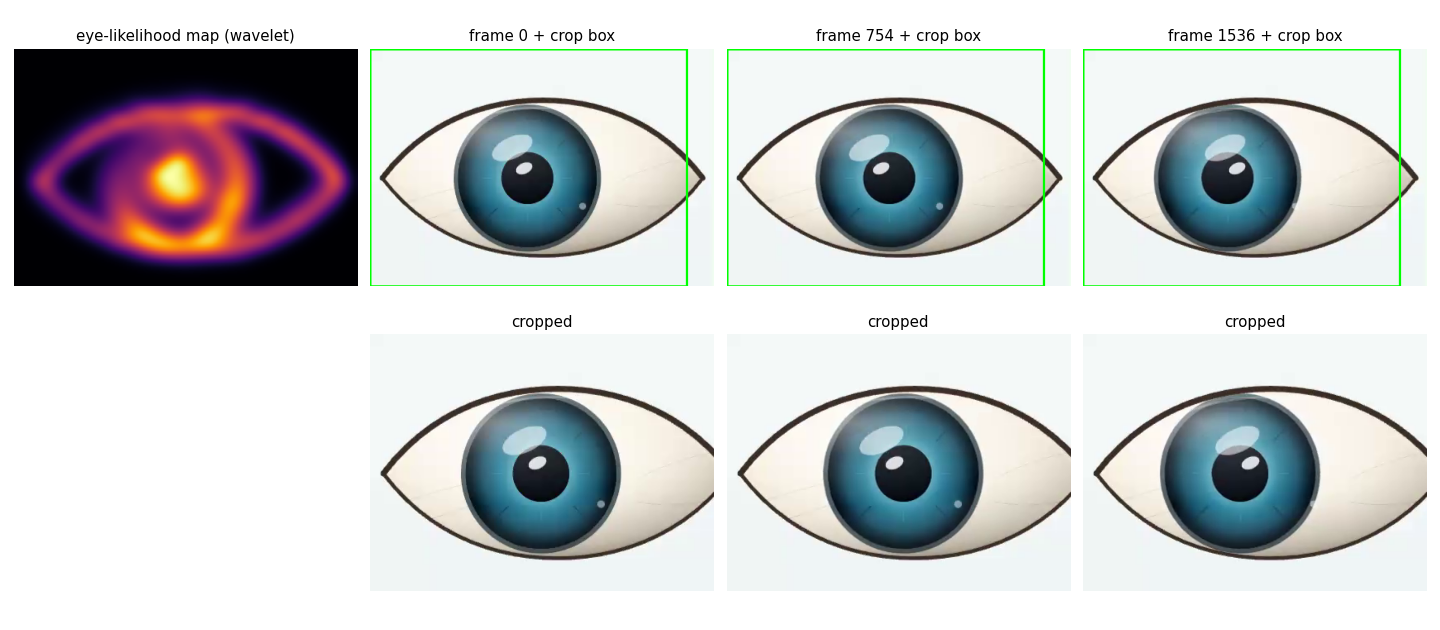

The pupil should be inside the green box in ALL frames (open AND closed). If not, raise CROP_SCALE and rerun.


In [10]:
# ===================== CELL 1: wavelet eye finder + 4:3 crop of blinkVid =====================
import subprocess, sys, shutil
try:
    import pywt
except Exception:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "PyWavelets"], check=True)
    import pywt
import cv2, numpy as np
from pathlib import Path
from IPython.display import Image, display
import matplotlib.pyplot as plt

blinkVid = "/kaggle/input/datasets/rzridazahra/mawa-dataset-2/animated_videos/Right_beating_horizontal_nystamus.mp4" 

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
PRE_VIDEO = blinkVid
PRE_OUT = WORK / "cropped_eye.mp4"
N_SAMPLES = 60           # frames analysed (a few closed-eye frames in there are harmless)
CROP_SCALE = 2.5         # crop width = CROP_SCALE x detected eye width (bigger = looser crop)
MIN_CROP_FRAC = 0.4      # crop never narrower than this fraction of the biggest possible 4:3 window
WAVELET, LEVELS = "db2", 3
ANALYSIS_W = 256

def _opens(p):
    c = cv2.VideoCapture(str(p)); ok = c.isOpened() and c.read()[0]; c.release(); return ok

if not _opens(PRE_VIDEO):                            # some .mov codecs: convert once with ffmpeg
    try:
        import imageio_ffmpeg
    except Exception:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imageio-ffmpeg"], check=True)
        import imageio_ffmpeg
    _ff = shutil.which("ffmpeg") or imageio_ffmpeg.get_ffmpeg_exe()
    _conv = WORK / "blinkVid_converted.mp4"
    subprocess.run([_ff, "-y", "-i", str(PRE_VIDEO), "-an", "-vcodec", "libx264", "-pix_fmt", "yuv420p", str(_conv)],
                   capture_output=True)
    PRE_VIDEO = str(_conv)

cap = cv2.VideoCapture(str(PRE_VIDEO))
W, H = int(cap.get(3)), int(cap.get(4))
FPS_IN = cap.get(cv2.CAP_PROP_FPS) or 30.0
N_IN = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
want = set(np.linspace(0, max(N_IN - 1, 0), N_SAMPLES).astype(int).tolist())
samples, sample_idx, i = [], [], 0
while True:
    ok, f = cap.read()
    if not ok: break
    if i in want: samples.append(f); sample_idx.append(i)
    i += 1
cap.release(); N_IN = i
print(f"blinkVid: {W}x{H}, {FPS_IN:.1f} fps, {N_IN} frames; analysing {len(samples)} sample frames")

AW = min(ANALYSIS_W, W); AH = int(round(H * AW / W)); SC = W / AW

def eye_score_map(bgr):
    """High where the image is DARK (pupil/iris) AND rich in wavelet edge energy (lids, lashes, glints)."""
    g = cv2.resize(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY), (AW, AH), interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
    coeffs = pywt.wavedec2(g, WAVELET, level=LEVELS)
    energy = np.zeros((AH, AW), np.float32)
    for (cH, cV, cD) in coeffs[1:]:
        e = np.sqrt(cH ** 2 + cV ** 2 + cD ** 2).astype(np.float32)
        energy += cv2.resize(e, (AW, AH), interpolation=cv2.INTER_LINEAR)
    energy = cv2.GaussianBlur(energy, (0, 0), max(AH, AW) / 40)
    energy /= energy.max() + 1e-9
    a = cv2.resize(coeffs[0].astype(np.float32), (AW, AH), interpolation=cv2.INTER_LINEAR)
    a = (a - a.min()) / (a.max() - a.min() + 1e-9)
    s = (1.0 - a) * energy
    m = int(0.05 * min(AH, AW))
    s[:m, :] = 0; s[-m:, :] = 0; s[:, :m] = 0; s[:, -m:] = 0
    return s / (s.max() + 1e-9)

heat_map = cv2.GaussianBlur(np.mean([eye_score_map(f) for f in samples], axis=0), (0, 0), max(AH, AW) / 50)
py, px = np.unravel_index(np.argmax(heat_map), heat_map.shape)
mask = (heat_map >= 0.5 * heat_map.max()).astype(np.uint8)
_, lab = cv2.connectedComponents(mask)
ys, xs = np.nonzero(lab == lab[py, px])
ew = max(xs.max() - xs.min() + 1, (ys.max() - ys.min() + 1) * 4 / 3)
cx, cy, ew = px * SC, py * SC, ew * SC
print(f"Wavelet: eye centre ~ ({cx:.0f}, {cy:.0f}) px   eye width ~ {ew:.0f} px")

# 4:3 crop, sizes multiples of (8, 6); a pure cut (no rescaling)
k_max = int(min(W // 8, H // 6))
k = int(np.clip(round(CROP_SCALE * ew / 8), max(1, int(MIN_CROP_FRAC * k_max)), k_max))
CW_PRE, CH_PRE = 8 * k, 6 * k
PRE_X0 = int(np.clip(round(cx - CW_PRE / 2), 0, W - CW_PRE))
PRE_Y0 = int(np.clip(round(cy - CH_PRE / 2), 0, H - CH_PRE))
print(f"Crop box (x0, y0, w, h) = ({PRE_X0}, {PRE_Y0}, {CW_PRE}, {CH_PRE}) of the {W}x{H} frame")

# preview PNG
show = np.linspace(0, len(samples) - 1, min(3, len(samples))).astype(int)
fig, axes = plt.subplots(2, len(show) + 1, figsize=(4 * (len(show) + 1), 7), squeeze=False)
axes[0, 0].imshow(heat_map, cmap="inferno"); axes[0, 0].set_title("eye-likelihood map (wavelet)"); axes[0, 0].axis("off")
axes[1, 0].axis("off")
for j, s_i in enumerate(show, start=1):
    rgb = cv2.cvtColor(samples[s_i], cv2.COLOR_BGR2RGB); full = rgb.copy()
    cv2.rectangle(full, (PRE_X0, PRE_Y0), (PRE_X0 + CW_PRE, PRE_Y0 + CH_PRE), (0, 255, 0), max(2, W // 200))
    axes[0, j].imshow(full); axes[0, j].set_title(f"frame {sample_idx[s_i]} + crop box"); axes[0, j].axis("off")
    axes[1, j].imshow(rgb[PRE_Y0:PRE_Y0 + CH_PRE, PRE_X0:PRE_X0 + CW_PRE]); axes[1, j].set_title("cropped"); axes[1, j].axis("off")
plt.tight_layout()
PREVIEW = WORK / "precrop_preview.png"
fig.savefig(PREVIEW, dpi=90); plt.close(fig); display(Image(str(PREVIEW)))
print("The pupil should be inside the green box in ALL frames (open AND closed). If not, raise CROP_SCALE and rerun.")

In [11]:
# ===================== CELL 2 (EllSeg): cropped video -> EllSeg, blink + occlusion aware =====================
import os, sys, subprocess, shutil, warnings, argparse
from pathlib import Path
import numpy as np

# ---- NumPy compatibility patch: MUST run before importing EllSeg / DeepVOG (they use np.int, np.float, ...) ----
for _n, _v in [("float", float), ("int", int), ("int0", np.intp), ("mat", np.asmatrix), ("bool", bool), ("object", object)]:
    if not hasattr(np, _n): setattr(np, _n, _v)

try:
    _need = (PRE_VIDEO, PRE_OUT, PRE_X0, PRE_Y0, CW_PRE, CH_PRE, FPS_IN)
except NameError:
    raise RuntimeError("Run Cell 1 first (the same wavelet-crop cell as before).")

MAX_FRAMES = None      # e.g. 200 for a quick test
STEP = 1               # render every Nth frame in the result video

# ---- EllSeg settings ----
WEIGHTS = "all.git_ok"      # pretrained weights that ship inside the repo (trained on all datasets)
ELLIPSES = 1                # 1 = EllSeg's own ellipses (inferred, so robust to occlusion) | 0 = ellipse fitted on the mask

# ---- blink / occlusion settings ----
BLINK_MIN_CONTRAST_FRAC = 0.25  # blink = (surround - pupil) contrast < this x typical open-eye contrast (pupil ~fully covered)
BLINK_MAX_AXIS_RATIO = 3.0      # ... or the ellipse is a sliver
BLINK_PAD = 2                   # frames also flagged either side of a blink
PARTIAL_OCC = 0.25              # occlusion score above this (but not a blink) = half-closed / partially covered
MAX_GAP_S = 0.6                 # blink gaps up to this long are bridged by interpolation

# ---- gaze angles: EXACTLY the DeepVOG method (same fitter, same constants, same angle function) ----
FOCAL_LENGTH_MM = 6.0; SENSOR_MM = (3.6, 4.8)      # identical to the DeepVOG cell
MIN_FIT_FRAMES = 100; MAX_FIT_FRAMES = 800         # identical to the DeepVOG cell
FIT_MAX_AXIS_RATIO = 1.6                           # network-independent rule for frames that may enter the eyeball fit
FLIP_HORIZONTAL = False; FLIP_VERTICAL = False; WINDOW = 150

OUT_DIR = WORK / "final_op_ellseg"; OUT_DIR.mkdir(parents=True, exist_ok=True)
REPO = WORK / "EllSeg"
NET_H, NET_W = 240, 320

# ---- cut the cropped eye video (pure cut, identical to the DeepVOG pipeline) ----
import cv2
cap = cv2.VideoCapture(str(PRE_VIDEO))
wr = cv2.VideoWriter(str(PRE_OUT), cv2.VideoWriter_fourcc(*"mp4v"), FPS_IN, (CW_PRE, CH_PRE)); n_w = 0
while True:
    ok_, f = cap.read()
    if not ok_: break
    wr.write(f[PRE_Y0:PRE_Y0 + CH_PRE, PRE_X0:PRE_X0 + CW_PRE]); n_w += 1
cap.release(); wr.release()
print(f"Cropped video: {PRE_OUT} ({n_w} frames, {CW_PRE}x{CH_PRE})")

# ---- get EllSeg + load the pretrained network ----
if not REPO.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/RSKothari/EllSeg.git", str(REPO)], check=True)
W_PATH = REPO / "weights" / WEIGHTS
if not W_PATH.exists() or W_PATH.stat().st_size < 1_000_000:
    print("Files in", REPO / "weights", ":", sorted(p.name for p in (REPO / "weights").glob("*")) if (REPO / "weights").exists() else "folder missing")
    raise FileNotFoundError(f"Pretrained weights not found / too small: {W_PATH}. Pick one of the files listed above via WEIGHTS = '...'")

import torch
warnings.filterwarnings("ignore")
sys.path.insert(0, str(REPO))
import evaluate_ellseg as ES                     # the repo's own inference code
from modelSummary import model_dict
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
try:
    netDict = torch.load(str(W_PATH), map_location=device, weights_only=False)
except TypeError:
    netDict = torch.load(str(W_PATH), map_location=device)
model = model_dict["ritnet_v3"]
model.load_state_dict(netDict["state_dict"], strict=True)
model.to(device).eval()
ES.args = argparse.Namespace(ellseg_ellipses=ELLIPSES, skip_ransac=0)   # evaluate_ellseg_on_image reads this global
print("EllSeg loaded on", device)

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import pandas as pd
from scipy.ndimage import binary_dilation
from IPython.display import Video, display

def get_ffmpeg():
    exe = shutil.which("ffmpeg")
    if exe: return exe
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imageio-ffmpeg"], check=True)
    import imageio_ffmpeg
    return imageio_ffmpeg.get_ffmpeg_exe()
FFMPEG = get_ffmpeg()

SRC = Path(PRE_OUT)
_c = cv2.VideoCapture(str(SRC))
VID_W, VID_H = int(_c.get(3)), int(_c.get(4)); FPS = _c.get(cv2.CAP_PROP_FPS) or 30.0
_c.release()
X0, Y0, CW, CH = 0, 0, VID_W, VID_H              # the whole cropped frame is the eye region (4:3)

def frames(path, max_frames=None):
    cap = cv2.VideoCapture(str(path)); i = 0
    while True:
        ok_, f = cap.read()
        if not ok_ or (max_frames is not None and i >= max_frames): break
        yield cv2.cvtColor(f, cv2.COLOR_BGR2RGB); i += 1
    cap.release()

def prep(rgb):
    """EllSeg input: grayscale 240x320, zero-mean / unit-std, shape [1,1,H,W]. (The crop is already 4:3: no padding needed.)"""
    g = cv2.resize(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), (NET_W, NET_H), interpolation=cv2.INTER_LANCZOS4)
    gf = g.astype(np.float32)
    return g, torch.from_numpy((gf - gf.mean()) / (gf.std() + 1e-6)).unsqueeze(0).unsqueeze(0)

def pupil_contrast(g, pm):
    """(surround - pupil) / surround, measured on the REAL pixels under EllSeg's pupil mask.
    Open eye: pupil is clearly darker than its ring -> high. Closed / covered by lid: skin under the mask -> ~0."""
    n = int(pm.sum())
    if n < 20: return np.nan
    r = max(3, int(0.6 * np.sqrt(n / np.pi)))
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))
    ring = (cv2.dilate(pm.astype(np.uint8), k) > 0) & ~pm
    if ring.sum() < 10: return np.nan
    inside, outside = float(g[pm].mean()), float(g[ring].mean())
    return (outside - inside) / max(outside, 1.0)

# ---- run EllSeg on EVERY frame (nothing is dropped) ----
pe_l, ie_l, con_l, seg_l = [], [], [], []

def valid_ellipse(e):
    e = np.asarray(e, float)
    return bool(e.shape[0] >= 5 and np.all(np.isfinite(e[:5])) and e[2] > 1 and e[3] > 1 and 0 <= e[0] < NET_W and 0 <= e[1] < NET_H)

nan5 = np.full(5, np.nan)
with torch.no_grad():
    for i, f in enumerate(frames(SRC, MAX_FRAMES)):
        g, t_in = prep(f)
        pe, ie, con, seg_s = nan5, nan5, np.nan, np.zeros((NET_H // 2, NET_W // 2), np.uint8)
        if g.max() >= 20:                                     # (the repo also skips almost-black frames)
            try:
                seg, _, pe_, ie_ = ES.evaluate_ellseg_on_image(t_in.to(device), model)
                pe_ = np.asarray(pe_, float).reshape(-1)[:5]; ie_ = np.asarray(ie_, float).reshape(-1)[:5]
                seg = np.asarray(seg)
                seg_s = seg[::2, ::2].astype(np.uint8)        # 0 background, 1 iris, 2 pupil
                con = pupil_contrast(g, seg == 2)
                if valid_ellipse(pe_): pe = pe_
                if valid_ellipse(ie_): ie = ie_
            except Exception as exc:
                if i == 0: print("First-frame error:", repr(exc)[:300])
        pe_l.append(pe); ie_l.append(ie); con_l.append(con); seg_l.append(seg_s)
        if (i + 1) % 100 == 0: print(f"\r  processed {i + 1} frames", end="", flush=True)

N = len(pe_l)
pe_arr, ie_arr, contrast = np.array(pe_l), np.array(ie_l), np.array(con_l, float)
found = np.isfinite(pe_arr[:, 0])
print(f"\nFrames: {N}  pupil ellipse returned in {int(found.sum())} ({100 * found.mean():.1f}%)")
if not found.any(): raise RuntimeError("EllSeg returned no ellipse in any frame - check the crop preview from Cell 1.")

area = np.pi * pe_arr[:, 2] * pe_arr[:, 3]                     # predicted (FULL) pupil ellipse area, network px^2
ratio = np.maximum(pe_arr[:, 2], pe_arr[:, 3]) / np.maximum(np.minimum(pe_arr[:, 2], pe_arr[:, 3]), 1e-6)

# ---- BLINK + OCCLUSION DETECTION ----
ref_area = np.nanpercentile(area[found], 75)
ref_con = np.nanpercentile(contrast[np.isfinite(contrast)], 75) if np.isfinite(contrast).any() else 1.0
bad = (~found) | (~np.isfinite(contrast)) | (contrast < BLINK_MIN_CONTRAST_FRAC * ref_con) \
      | (np.nan_to_num(ratio, nan=1.0) > BLINK_MAX_AXIS_RATIO)      # (no area rule: EllSeg ellipse size jumps, it made open eyes look like blinks)
blink = binary_dilation(bad, structure=np.ones(2 * BLINK_PAD + 1, bool))
occl = np.clip(1.0 - np.nan_to_num(contrast, nan=0.0) / max(ref_con, 1e-6), 0, 1)     # 0 = clear pupil, 1 = fully covered
partial = (occl > PARTIAL_OCC) & ~blink & found
n_events = int(np.sum(np.diff(np.r_[0, blink.astype(int)]) == 1))
print(f"Blink frames: {int(blink.sum())}/{N} ({100 * blink.mean():.1f}%) in {n_events} event(s) | "
      f"partially occluded (ellipse still returned): {int(partial.sum())} frames")
print(f"  reference open-eye contrast {ref_con:.2f}, pupil ellipse area ~ {ref_area:.0f} px^2")

# ---- per-frame results ----
pupil_net = pe_arr[:, :2].copy()
valid = found & ~blink
pupil_x = X0 + pupil_net[:, 0] * (CW / NET_W); pupil_y = Y0 + pupil_net[:, 1] * (CH / NET_H)   # cropped-video px
pupil_x_orig = pupil_x + PRE_X0; pupil_y_orig = pupil_y + PRE_Y0                                 # original-video px

# ===================== gaze angles through the DeepVOG eyeball-model pipeline =====================
DV_REPO = WORK / "DeepVOG"
if not DV_REPO.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pydsgz/DeepVOG.git", str(DV_REPO)], check=True)
sys.path.append(str(DV_REPO))                       # append: EllSeg's own modules keep priority
import types
def _import_fitter():
    # Import only the numpy fitter modules. A stub package skips deepvog/__init__.py (which pulls in TensorFlow/Keras).
    if "deepvog" not in sys.modules:
        _pkg = types.ModuleType("deepvog"); _pkg.__path__ = [str(DV_REPO / "deepvog")]; sys.modules["deepvog"] = _pkg
    from deepvog.eyefitter import SingleEyeFitter
    from deepvog.ellipses import LSqEllipse
    return SingleEyeFitter, LSqEllipse
try:
    SingleEyeFitter, LSqEllipse = _import_fitter()
except Exception as _exc:
    print("Stub import failed (", repr(_exc)[:120], ") -> importing the full deepvog package (needs TensorFlow)")
    for _k in [k for k in sys.modules if k == "deepvog" or k.startswith("deepvog.")]: del sys.modules[_k]
    from deepvog.eyefitter import SingleEyeFitter
    from deepvog.ellipses import LSqEllipse
def _safe_params(self):
    c = self._center
    return (np.array([np.real(c[0]), np.real(c[1])], dtype=float),
            float(np.real(self._width)), float(np.real(self._height)), float(np.real(self._phi)))
LSqEllipse.parameters = _safe_params

MM2PX = np.linalg.norm((NET_H, NET_W)) / np.linalg.norm(SENSOR_MM)
fitter = SingleEyeFitter(focal_length=FOCAL_LENGTH_MM * MM2PX, pupil_radius=2.0 * MM2PX, initial_eye_z=50.0 * MM2PX)

# ---- SHARED ANGLE FUNCTION: byte-for-byte identical in the DeepVOG and EllSeg pipelines ----
def vec_to_angles(n):
    n = np.asarray(n, float).reshape(3); n = n / np.linalg.norm(n)
    h = np.degrees(np.arctan2(n[0], abs(n[2])))         # + = right
    v = np.degrees(-np.arcsin(np.clip(n[1], -1, 1)))    # + = up
    return h, v

# ---- EllSeg full ellipse -> filled 240x320 map (what DeepVOG's network would have produced) ----
SS = 4                                               # 4x supersampling -> sub-pixel accurate edge
def ellipse_to_map(e):
    cx, cy, a_, b_, th = e                           # EllSeg: centre, SEMI-axes, angle in radians
    m = np.zeros((NET_H * SS, NET_W * SS), np.uint8)
    cv2.ellipse(m, (int(round(cx * SS)), int(round(cy * SS))),
                (max(1, int(round(a_ * SS))), max(1, int(round(b_ * SS)))), float(np.degrees(th)), 0, 360, 255, -1)
    return cv2.resize(m, (NET_W, NET_H), interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0

obs = [None] * N
with np.errstate(all="ignore"):
    for i in range(N):
        if not found[i]: continue
        try:
            gp, gn, pp, pn, (rr, cc, centre, w, h, rad, conf_) = fitter.unproject_single_observation(ellipse_to_map(pe_arr[i]))
            if centre is not None and all(x is not None and np.all(np.isfinite(x)) for x in [gp, gn, pp, pn]):
                obs[i] = dict(centre=(float(centre[0]), float(centre[1])), gp=gp.copy(), gn=gn.copy(), pp=pp.copy(), pn=pn.copy())
        except Exception:
            obs[i] = None

def load_obs(o):
    fitter.current_gaze_pos, fitter.current_gaze_neg = o["gp"], o["gn"]
    fitter.current_pupil_3Dcentre_pos, fitter.current_pupil_3Dcentre_neg = o["pp"], o["pn"]
    fitter.current_ellipse_centre = np.array(o["centre"]).reshape(2, 1)

# ---- eyeball model: fitted ONLY on clear open-eye frames (no blink, no partial occlusion, sane ellipse shape) ----
ok_fit = np.array([o is not None for o in obs]) & ~blink & ~partial & (np.nan_to_num(ratio, nan=9.0) < FIT_MAX_AXIS_RATIO)
sel = np.flatnonzero(ok_fit)
if sel.size > MAX_FIT_FRAMES: sel = sel[np.linspace(0, sel.size - 1, MAX_FIT_FRAMES).astype(int)]
print(f"Eyeball fit: {sel.size} clear open-eye frames (want >= {MIN_FIT_FRAMES})")

HAVE_ANGLES = False
if sel.size >= 10:
    np.random.seed(0)
    for i in sel:
        load_obs(obs[i]); fitter.add_to_fitting()
    try:
        with np.errstate(all="ignore"):
            try: fitter.fit_projected_eye_centre(ransac=True, max_iters=100, min_distance=max(2000, 10 * N))
            except TypeError: fitter.fit_projected_eye_centre(ransac=False)
            fitter.estimate_eye_sphere()
        ec, er = np.asarray(fitter.eye_centre).reshape(-1), float(fitter.aver_eye_radius)
        radius_mm = er / MM2PX
        print(f"Eyeball model fitted, radius ~ {radius_mm:.1f} mm (human eye ~12 mm)")
        if np.all(np.isfinite(ec)) and np.isfinite(er) and er > 0 and ec[2] > 0 and 6 <= radius_mm <= 20:
            HAVE_ANGLES = True
        else:
            print("  Eyeball fit implausible (too little eye movement?) -> NO angles; graphs use pupil position (px).")
    except Exception as exc:
        print("Eyeball fit failed:", repr(exc)[:200])
if not HAVE_ANGLES: print("No eyeball model -> graphs use pupil position (px) instead of angles.")

hor = np.full(N, np.nan); ver = np.full(N, np.nan); consist = np.zeros(N, dtype=int)
if HAVE_ANGLES:
    with np.errstate(all="ignore"):
        for i, o in enumerate(obs):
            if o is None or blink[i]: continue                # no gaze value on blink frames
            try:
                load_obs(o)
                _, n_list, _, ok = fitter.gen_consistent_pupil()
                if bool(ok):                                  # ray misses the fitted eyeball -> NaN (never use the fallback vector)
                    h_, v_ = vec_to_angles(n_list[0])
                    if np.isfinite(h_) and np.isfinite(v_):
                        hor[i], ver[i], consist[i] = h_, v_, 1
            except Exception:
                pass
if FLIP_HORIZONTAL: hor = -hor
if FLIP_VERTICAL: ver = -ver
valid = found & ~blink
if HAVE_ANGLES:
    valid &= np.isfinite(hor) & np.isfinite(ver)
    c = consist[found & ~blink].mean()
    print(f"Gaze consistent on {100 * c:.0f}% of open-eye frames")
    if c < 0.6: print("  WARNING: poor eyeball fit -> treat gaze ANGLES with care.")
print(f"Valid frames: {int(valid.sum())}/{N}")

Cropped video: /kaggle/working/cropped_eye.mp4 (1537 frames, 416x312)
EllSeg loaded on cuda
  processed 1500 frames
Frames: 1537  pupil ellipse returned in 1537 (100.0%)
Blink frames: 0/1537 (0.0%) in 0 event(s) | partially occluded (ellipse still returned): 0 frames
  reference open-eye contrast 0.70, pupil ellipse area ~ 2192 px^2
Eyeball fit: 800 clear open-eye frames (want >= 100)
Eyeball model fitted, radius ~ 4.0 mm (human eye ~12 mm)
  Eyeball fit implausible (too little eye movement?) -> NO angles; graphs use pupil position (px).
No eyeball model -> graphs use pupil position (px) instead of angles.
Valid frames: 1537/1537


In [12]:
# ===================== CELL 3 (EllSeg, lean): extract eye-movement values -> one small CSV =====================
from scipy.signal import savgol_filter

VEL_WIN_S = 0.10          # Savitzky-Golay window for velocity (s)
QP_VEL = 40.0             # deg/s quick-phase threshold, used only when real angles exist (px mode picks its own)
QP_PAD = 2                # frames removed around each quick phase before SPV
SPV_WIN_S = 1.0           # SPV = median slow-phase velocity in a sliding window (s)
APPROX_DEG = True         # always output degrees: if no eyeball model, px is converted to degrees (iris size as ruler)
IRIS_DIAM_MM = 11.7; EYE_R_MM = 12.0   # only used when APPROX_DEG = True

def fill_gaps(x, max_gap):
    x = np.asarray(x, float); out = x.copy(); n = len(x); ok = np.isfinite(x)
    if ok.sum() < 2: return out
    idx = np.arange(n); filled = np.interp(idx, idx[ok], x[ok]); i = 0
    while i < n:
        if ok[i]: i += 1; continue
        j = i
        while j < n and not ok[j]: j += 1
        if i > 0 and j < n and (j - i) <= max_gap: out[i:j] = filled[i:j]
        i = j
    return out

def velocity(x, fps):
    x = np.asarray(x, float); ok = np.isfinite(x)
    if ok.sum() < 7: return np.full(len(x), np.nan)
    xi = np.interp(np.arange(len(x)), np.flatnonzero(ok), x[ok])
    w = max(5, int(round(VEL_WIN_S * fps))); w += (w % 2 == 0)
    if w > len(x): w = len(x) - (len(x) % 2 == 0)
    v = savgol_filter(xi, w, 2, deriv=1, delta=1.0 / fps); v[~ok] = np.nan
    return v

def qp_threshold(v):
    d = np.abs(v - np.nanmedian(v)); d = d[np.isfinite(d)]
    if d.size == 0: return np.inf
    return max(5 * 1.4826 * np.median(d), 0.3 * np.percentile(d, 99))

def slow_phase_velocity(v, thr, fps):
    base = np.nanmedian(v)
    quick = np.isfinite(v) & (np.abs(v - base) > thr)
    pad = binary_dilation(quick, structure=np.ones(2 * QP_PAD + 1, bool))
    slow = np.where(np.isfinite(v) & ~pad, v, np.nan)
    win = max(5, int(round(SPV_WIN_S * fps)))
    spv = pd.Series(slow).rolling(win, center=True, min_periods=max(3, win // 5)).median().to_numpy()
    return spv, quick

t = np.arange(N) / FPS
max_gap = int(round(MAX_GAP_S * FPS))

# ---- signal: + = right, + = up (video view) ----
REAL_ANGLES = bool(HAVE_ANGLES)
if REAL_ANGLES:
    UNIT = "deg"; sh_raw, sv_raw = hor.copy(), ver.copy(); sh_raw[~valid] = np.nan; sv_raw[~valid] = np.nan
else:
    UNIT = "px"
    sh_raw = np.where(valid, pupil_x, np.nan); sv_raw = np.where(valid, -pupil_y, np.nan)
    sh_raw = sh_raw - np.nanmedian(sh_raw); sv_raw = sv_raw - np.nanmedian(sv_raw)
    if APPROX_DEG:
        _ir = np.maximum(ie_arr[:, 2], ie_arr[:, 3]); _ir = _ir[np.isfinite(_ir)]
        if _ir.size > 10:
            mm_per_px = IRIS_DIAM_MM / (2 * np.median(_ir) * (CW / NET_W))
            sh_raw = np.degrees(np.arcsin(np.clip(sh_raw * mm_per_px / EYE_R_MM, -1, 1)))
            sv_raw = np.degrees(np.arcsin(np.clip(sv_raw * mm_per_px / EYE_R_MM, -1, 1)))
            UNIT = "deg"

H_i, V_i = fill_gaps(sh_raw, max_gap), fill_gaps(sv_raw, max_gap)       # blink gaps bridged
vel_h, vel_v = velocity(H_i, FPS), velocity(V_i, FPS)
speed = np.hypot(vel_h, vel_v)
thr_h = QP_VEL if REAL_ANGLES else qp_threshold(vel_h)
thr_v = QP_VEL if REAL_ANGLES else qp_threshold(vel_v)
spv_h, quick_h = slow_phase_velocity(vel_h, thr_h, FPS)
spv_v, quick_v = slow_phase_velocity(vel_v, thr_v, FPS)

# ===== OUTPUT: lean CSV (values only) =====
df = pd.DataFrame({
    "time_s": t, "hor_interp": H_i, "ver_interp": V_i, "speed_s": speed,
    "vel_h_s": vel_h, "vel_v_s": vel_v, "spv_h_s": spv_h, "spv_v_s": spv_v,
    "quick_phase_h": quick_h.astype(int), "quick_phase_v": quick_v.astype(int),
    "blink": blink.astype(int), "unit": UNIT,      # px, deg~ (approx.) or deg (real eyeball-model angles)
}).round(4)
df.to_csv(OUT_DIR / "final_op_ellseg.csv", index=False)
print(f"Saved: {OUT_DIR / 'final_op_ellseg.csv'} | {N} frames | unit = {UNIT} (position {UNIT}, velocity/SPV/speed {UNIT}/s)")

Saved: /kaggle/working/final_op_ellseg/final_op_ellseg.csv | 1537 frames | unit = deg (position deg, velocity/SPV/speed deg/s)


# ===================== CELL 4 (EllSeg): final_op_ellseg.mp4 =====================
PANELS = [
    (f"Horizontal gaze ({UNIT}, + = right)", [(H_i, "#4c72b0")]),
    (f"Vertical gaze ({UNIT}, + = up)",      [(V_i, "#b0409a")]),
    (f"Velocity ({UNIT}/s)  H / V",          [(vel_h, "#4c72b0"), (vel_v, "#b0409a")]),
    (f"SPV ({UNIT}/s)  H / V",               [(spv_h, "#4c72b0"), (spv_v, "#b0409a")]),
    ("Occlusion score (0 clear - 1 covered)", [(occl, "#d62728")]),
]
lims = []
for _, ser in PANELS:
    allv = np.concatenate([s for s, _ in ser]); allv = allv[np.isfinite(allv)]
    lo, hi = (allv.min(), allv.max()) if allv.size else (-1, 1)
    pad = 0.1 * (hi - lo if hi > lo else 1.0); lims.append((lo - pad, hi + pad))
sc = max(np.nanpercentile(np.abs(H_i), 99), np.nanpercentile(np.abs(V_i), 99), 1e-6)

RAW, FINAL = OUT_DIR / "final_op_ellseg_raw.mp4", OUT_DIR / "final_op_ellseg.mp4"
fig = plt.figure(figsize=(12, 6.6), dpi=80)
gs = GridSpec(2, 3, width_ratios=[1.1, 1.3, 2.6], figure=fig, wspace=0.15, hspace=0.25)
ax_img = [fig.add_subplot(gs[i, 0]) for i in range(2)]
ax_eye = fig.add_subplot(gs[:, 1])
gs_r = gs[:, 2].subgridspec(len(PANELS), 1, hspace=1.0)
ax_p = [fig.add_subplot(gs_r[i]) for i in range(len(PANELS))]
fig.canvas.draw(); W_PX, H_PX = fig.canvas.get_width_height()
writer = cv2.VideoWriter(str(RAW), cv2.VideoWriter_fourcc(*"mp4v"), max(FPS / STEP, 1), (W_PX, H_PX))

for i, f in enumerate(frames(SRC, MAX_FRAMES)):
    if i >= N: break
    if i % STEP: continue
    im = f
    if im.shape[1] > 320: im = cv2.resize(im, (320, int(im.shape[0] * 320 / im.shape[1])), interpolation=cv2.INTER_AREA)
    sx, sy = im.shape[1] / NET_W, im.shape[0] / NET_H
    ov = im.copy()
    seg = cv2.resize(seg_l[i], (im.shape[1], im.shape[0]), interpolation=cv2.INTER_NEAREST)
    ov[seg == 1] = (0.6 * ov[seg == 1] + 0.4 * np.array([60, 90, 255])).astype(np.uint8)     # iris  = blue
    ov[seg == 2] = (0.5 * ov[seg == 2] + 0.5 * np.array([255, 60, 60])).astype(np.uint8)     # pupil = red
    pe = pe_arr[i]
    if np.isfinite(pe[0]) and not blink[i]:
        cv2.ellipse(ov, (int(pe[0] * sx), int(pe[1] * sy)), (max(1, int(pe[2] * sx)), max(1, int(pe[3] * sy))),
                    float(np.degrees(pe[4])), 0, 360, (255, 255, 0), 1)
        cv2.drawMarker(ov, (int(pe[0] * sx), int(pe[1] * sy)), (0, 255, 0), cv2.MARKER_CROSS, 10, 1)
    if blink[i]: cv2.putText(ov, "BLINK", (8, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)
    elif partial[i]: cv2.putText(ov, "PARTIAL OCCLUSION", (8, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 140, 0), 2)

    for a in ax_img + [ax_eye] + ax_p: a.clear()
    for a, (t_, pic) in zip(ax_img, [("Cropped eye video", im), ("EllSeg segmentation + pupil centre", ov)]):
        a.imshow(pic); a.set_title(t_, fontsize=8, loc="left", pad=2); a.axis("off")
    ax_eye.set_xlim(-1.3, 1.3); ax_eye.set_ylim(-1.3, 1.3); ax_eye.set_aspect("equal"); ax_eye.axis("off")
    ax_eye.add_patch(plt.Circle((0, 0), 1.2, color="#c8c8c8")); ax_eye.add_patch(plt.Circle((0, 0), 0.8, color="#f0b3f5"))
    if np.isfinite(H_i[i]) and np.isfinite(V_i[i]):
        ax_eye.annotate("", xy=(np.clip(0.8 * H_i[i] / sc, -1.1, 1.1), np.clip(0.8 * V_i[i] / sc, -1.1, 1.1)), xytext=(0, 0),
                        arrowprops=dict(arrowstyle="-|>", color="#c0392b" if blink[i] else "#1a1a3a", lw=2.5))
    ax_eye.add_patch(plt.Circle((0, 0), 0.12, fill=False, ec="k"))
    lo = max(0, i - WINDOW); xr = np.arange(lo, i + 1)
    for a, (name, ser), (ylo, yhi) in zip(ax_p, PANELS, lims):
        for s, c_ in ser: a.plot(xr, s[lo:i + 1], color=c_, lw=1.2)
        a.fill_between(xr, ylo, yhi, where=blink[lo:i + 1], color="red", alpha=0.15, lw=0)
        a.axhline(0, color="#bbb", lw=1); a.set_xlim(lo, lo + WINDOW); a.set_ylim(ylo, yhi)
        a.set_title(name, fontsize=8, pad=2, loc="left"); a.tick_params(labelsize=6)
        for sp in ("top", "right"): a.spines[sp].set_visible(False)
    txt = fig.text(0.97, 0.96, f"Frame: {i}", ha="right", fontsize=8)
    fig.canvas.draw()
    writer.write(cv2.cvtColor(np.asarray(fig.canvas.buffer_rgba())[..., :3], cv2.COLOR_RGB2BGR))
    txt.remove()

writer.release(); plt.close(fig)
r = subprocess.run([FFMPEG, "-y", "-i", str(RAW), "-vcodec", "libx264", "-pix_fmt", "yuv420p", str(FINAL)],
                   capture_output=True, text=True)
if r.returncode: raise RuntimeError("ffmpeg failed:\n" + r.stderr[-1500:])
RAW.unlink(missing_ok=True)
print("Saved:", FINAL)
display(Video(str(FINAL), embed=True, width=900))